# 09 — Market Regime Detection

**Goal:** cluster trailing return/volatility into low/medium/high-volatility
regimes, and show the difference between the **exploratory** (full-history)
and **walk-forward** (backtest-safe) fitting modes — see
`docs/DATA_LEAKAGE_AUDIT.md` §11 for why this distinction matters.

In [1]:
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams["figure.figsize"] = (10, 5)

np.random.seed(42)

from notebooks.nb_utils import fetch_price_panel

TICKERS = ["AAPL", "MSFT", "GLD", "BND", "SPY"]
START = "2019-01-01"

price_panel, used_synthetic = fetch_price_panel(TICKERS, START)
returns_panel = price_panel.pct_change().dropna()
print(f"Loaded {price_panel.shape[0]} rows x {price_panel.shape[1]} tickers. Synthetic data: {used_synthetic}")
price_panel.tail()

Failed to get ticker 'BND' reason: Expecting value: line 1 column 1 (char 0)


HTTP Error 403: Host not in allowlist: query2.finance.yahoo.com. Add this host to your network egress settings to allow access.


HTTP Error 403: Host not in allowlist: query1.finance.yahoo.com. Add this host to your network egress settings to allow access.


Failed to get ticker 'MSFT' reason: Expecting value: line 1 column 1 (char 0)


HTTP Error 403: Host not in allowlist: query2.finance.yahoo.com. Add this host to your network egress settings to allow access.


HTTP Error 403: Host not in allowlist: query1.finance.yahoo.com. Add this host to your network egress settings to allow access.


... (7 outputs left out)

['BND', 'MSFT']: JSONDecodeError('Expecting value: line 1 column 1 (char 0)')


['GLD', 'AAPL', 'SPY']: possibly delisted; no timezone found


[info] Live data unavailable (KeyError); using synthetic demo data instead.
Loaded 2004 rows x 5 tickers. Synthetic data: True


,AAPL,MSFT,GLD,BND,SPY
2026-08-31,229.681016,128.274867,119.914845,364.746718,107.728124
2026-09-01,227.093540,128.294744,120.000708,372.445526,106.711406
2026-09-02,229.155329,127.875189,121.085078,365.765614,106.991434
2026-09-03,232.958620,125.652809,122.697759,374.610608,107.656847
2026-09-04,232.705684,125.622649,120.900524,369.667262,106.661264


In [2]:
from src.features.feature_pipeline import build_features_for_asset
from src.models.regime import fit_exploratory_regimes, fit_walk_forward_regimes
from src.portfolio.analytics import portfolio_returns

weights = pd.Series(1 / len(TICKERS), index=TICKERS)
port_returns = portfolio_returns(returns_panel, weights)
wealth = (1 + port_returns).cumprod()

prices_df = wealth.reset_index()
prices_df.columns = ["date", "adj_close"]
prices_df["volume"] = 1

feats = build_features_for_asset(prices_df)
print(feats.dropna(subset=["ret_20d", "vol_20d"]).shape)

(1983, 19)


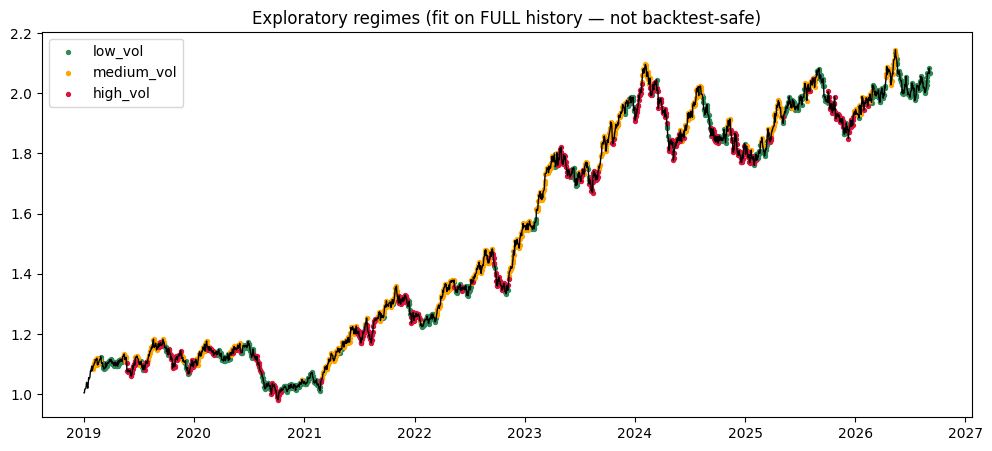

In [3]:
exploratory = fit_exploratory_regimes(feats, n_regimes=3).set_index("date")

color_map = {"low_vol": "seagreen", "medium_vol": "orange", "high_vol": "crimson"}
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(wealth.index, wealth.values, color="black", linewidth=1)
for label, color in color_map.items():
    mask = exploratory["regime_label"] == label
    ax.scatter(exploratory.index[mask], wealth.reindex(exploratory.index[mask]), color=color, s=8, label=label)
ax.legend()
ax.set_title("Exploratory regimes (fit on FULL history — not backtest-safe)")
plt.show()

In [4]:
walk_forward = fit_walk_forward_regimes(feats, min_train_days=252, refit_every_days=63)
print(f"Walk-forward regimes: {len(walk_forward)} labeled rows (first {252} days used only as warm-up training data, unlabeled)")
walk_forward["regime_label"].value_counts(normalize=True).mul(100).round(1)

Walk-forward regimes: 1731 labeled rows (first 252 days used only as warm-up training data, unlabeled)


regime_label
low_vol       38.5
medium_vol    34.9
high_vol      26.6
Name: proportion, dtype: float64

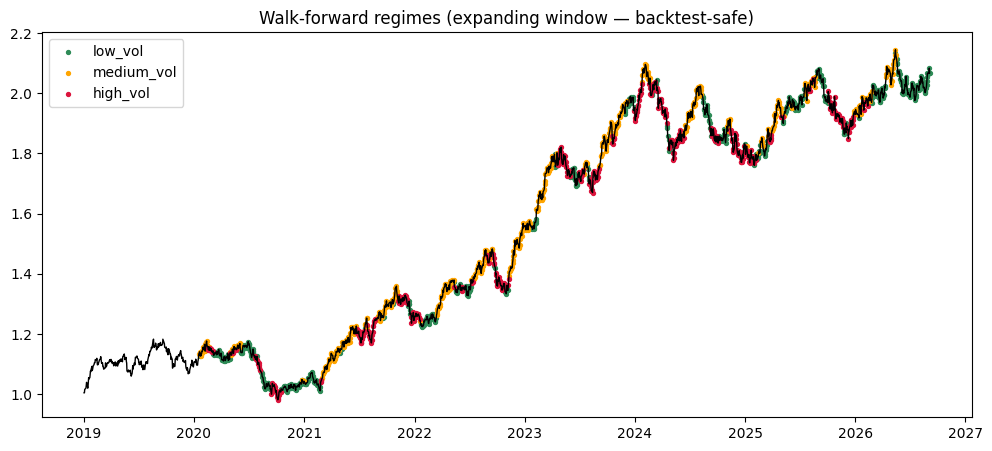

In [5]:
wf_indexed = walk_forward.set_index("date")
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(wealth.index, wealth.values, color="black", linewidth=1)
for label, color in color_map.items():
    mask = wf_indexed["regime_label"] == label
    ax.scatter(wf_indexed.index[mask], wealth.reindex(wf_indexed.index[mask]), color=color, s=8, label=label)
ax.legend()
ax.set_title("Walk-forward regimes (expanding window — backtest-safe)")
plt.show()

## Takeaways

- The exploratory version can label an EARLY calm period as 'high_vol' if a later, more extreme period redefines the cluster boundaries — impossible to know at the time, so it must never drive a backtested strategy.
- The walk-forward version only ever uses data through the current date, matching the guarantee needed for **12 — Walk-Forward Backtesting**.
- Continue to **10 — Portfolio Optimization**.